# Laboratório — GRU (Gated Recurrent Unit) e Comparação com LSTM e SimpleRNN


# Setup


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Definir sementes para reprodutibilidade
keras.utils.set_random_seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


# 1. Dataset: avaliações de produtos

Construiremos um pequeno conjunto balanceado de avaliações positivas (1) e negativas (0), dividido rigorosamente em Treino (32), Validação (8) e Teste (8).


In [2]:
positivos = [
    "produto muito bom", "gostei muito do produto", "qualidade excelente e acabamento bom",
    "produto funciona muito bem", "compra valeu a pena", "produto chegou perfeito",
    "material de boa qualidade", "produto superou minhas expectativas", "estou satisfeito com a compra",
    "recomendo este produto", "produto bonito e confortável", "ótimo produto para o preço",
    "funcionou perfeitamente", "produto fácil de usar", "boa qualidade e bom acabamento",
    "não tive problemas com o produto", "produto chegou rápido e funcionando", "gostei do acabamento",
    "vale muito a pena", "produto excelente", "muito satisfeito com o produto",
    "compra muito boa", "produto atende bem", "recomendo a compra"
]

negativos = [
    "produto muito ruim", "não gostei do produto", "qualidade péssima e acabamento ruim",
    "produto não funciona bem", "compra não valeu a pena", "produto chegou quebrado",
    "material de baixa qualidade", "produto ficou abaixo das expectativas", "estou insatisfeito com a compra",
    "não recomendo este produto", "produto desconfortável e frágil", "péssimo produto para o preço",
    "não funcionou corretamente", "produto difícil de usar", "baixa qualidade e acabamento ruim",
    "tive muitos problemas com o produto", "produto chegou com defeito", "não gostei do acabamento",
    "não vale a pena", "produto péssimo", "muito insatisfeito com o produto",
    "compra muito ruim", "produto não atende bem", "não recomendo a compra"
]

textos = np.array(positivos + negativos)
rotulos = np.array([1] * len(positivos) + [0] * len(negativos))

rng = np.random.default_rng(42)
idx_treino, idx_val, idx_teste = [], [], []
for classe in [0, 1]:
    idx = rng.permutation(np.flatnonzero(rotulos == classe))
    idx_treino.extend(idx[:16])
    idx_val.extend(idx[16:20])
    idx_teste.extend(idx[20:])

idx_treino = rng.permutation(idx_treino)
idx_val = rng.permutation(idx_val)
idx_teste = rng.permutation(idx_teste)

textos_treino, y_train = textos[idx_treino], rotulos[idx_treino]
textos_val, y_val = textos[idx_val], rotulos[idx_val]
textos_teste, y_test = textos[idx_teste], rotulos[idx_teste]

print(f"Treino: {len(textos_treino)} | Validação: {len(textos_val)} | Teste: {len(textos_teste)}")


Treino: 32 | Validação: 8 | Teste: 8


## Perguntas

**1.** Qual é a importância de garantir que o mesmo split de treino/validação/teste seja mantido ao comparar diferentes arquiteturas (SimpleRNN, LSTM e GRU)?


# 2. Pré-processamento e Vetorização

Fixaremos `T = 10` passos no tempo. Textos menores receberão *padding* (0) e maiores serão truncados.


In [3]:
T = 10

vectorizador = layers.TextVectorization(
    max_tokens=200, output_mode="int", output_sequence_length=T
)
vectorizador.adapt(textos_treino)

X_train = vectorizador(textos_treino).numpy()
X_val = vectorizador(textos_val).numpy()
X_test = vectorizador(textos_teste).numpy()
vocabulario = vectorizador.get_vocabulary()
V = len(vocabulario)

print(f"Tamanho do vocabulário V = {V}")
print(f"Shape de X_train: {X_train.shape}")


Tamanho do vocabulário V = 55
Shape de X_train: (32, 10)


## Perguntas

**2.** Sabendo que `X_train` possui formato `(32, 10)`, o que representam o número `32` e o número `10` no contexto de processamento de linguagem natural com redes recorrentes?


# 3. Anatomia da GRU e suas Portas

Diferente da LSTM, a GRU possui **apenas um estado oculto ($h_t$)** e **duas portas**:
1. **Porta de Redefinição (*Reset Gate* - $r_t$):** Decide quanto da memória passada ($h_{t-1}$) deve ser mantida ao calcular o candidato a novo estado.
2. **Porta de Atualização (*Update Gate* - $z_t$):** Decide o quanto do estado antigo ($h_{t-1}$) será mantido em relação ao novo candidato ($\tilde{h}_t$).

As equações fundamentais de um passo no tempo $t$ são:
$$
r_t = \sigma(W_r \cdot x_t + U_r \cdot h_{t-1} + b_r)
$$
$$
z_t = \sigma(W_z \cdot x_t + U_z \cdot h_{t-1} + b_z)
$$
$$
\tilde{h}_t = \tanh(W_h \cdot x_t + U_h \cdot (r_t \odot h_{t-1}) + b_h)
$$
$$
h_t = (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t
$$
*(Nota: No Keras, a convenção padrão calcula $h_t = (1 - z_t) \odot \tilde{h}_t + z_t \odot h_{t-1}$, mantendo o mesmo princípio de interpolação).* e o parâmetro `reset_after=True` altera levemente a aplicação do bias, mantendo o mesmo conceito.


In [4]:
d = 4
H = 8

embedding_demo = layers.Embedding(input_dim=V, output_dim=d, mask_zero=True)
amostra_ids = X_train[:1]
vetores_demo = embedding_demo(amostra_ids)

# Instanciar uma camada GRU não treinada para observar o fluxo
gru_demo = layers.GRU(H, return_sequences=True, return_state=True)
sequencia_h, h_final = gru_demo(vetores_demo)

print("Formato da sequência de estados h:", sequencia_h.shape)
print("Formato do estado h final:      ", h_final.shape)
print("Diferença para a LSTM: A GRU devolve apenas 1 estado (h), pois NÃO possui o Cell State (c) separado!")


Formato da sequência de estados h: (1, 10, 8)
Formato do estado h final:       (1, 8)
Diferença para a LSTM: A GRU devolve apenas 1 estado (h), pois NÃO possui o Cell State (c) separado!


## Perguntas

**3.** Qual a diferença fundamental entre os estados mantidos pela LSTM e pela GRU entre cada passo de tempo?  
**4.** Analise a equação do candidato $\tilde{h}_t$. O que acontece com a influência do passado $h_{t-1}$ se a porta de redefinição $r_t$ for próxima de 0?  
**5.** Analise a equação da atualização do estado final $h_t$. Se a porta de atualização $z_t$ for igual a 1 (na convenção onde $z_t$ multiplica $h_{t-1}$), o que acontece com a informação que atravessa a célula ao longo dos passos?


# 4. Contagem Manual de Parâmetros

Vamos comparar teoricamente a quantidade de parâmetros das camadas recorrentes para uma entrada de dimensão $d$ e $H$ neurônios:

- **SimpleRNN:** $1 \times H \times (d + H + 1)$
- **GRU:** $3 \times H \times (d + H + 1)$ *(devido às portas Reset, Update e Candidato)*
- **LSTM:** $4 \times H \times (d + H + 1)$ *(devido às portas Input, Forget, Output e Candidato)*


In [5]:
# Criar as três camadas para verificar os parâmetros exatos no Keras
rnn_layer = layers.SimpleRNN(H)
gru_layer = layers.GRU(H)
lstm_layer = layers.LSTM(H)

for layer in [rnn_layer, gru_layer, lstm_layer]:
    layer.build((None, T, d))

print(f"Parâmetros SimpleRNN (H={H}): {rnn_layer.count_params()}")
print(f"Parâmetros GRU       (H={H}): {gru_layer.count_params()}")
print(f"Parâmetros LSTM      (H={H}): {lstm_layer.count_params()}")

# Inspecionar os formatos das matrizes de pesos da GRU
W, U, b = gru_layer.get_weights()
print("\nFormatos dos pesos da GRU no Keras:")
print("W (Kernel entrada):    ", W.shape, " -> d x (3 * H)")
print("U (Kernel recorrente): ", U.shape, " -> H x (3 * H)")
print("b (Biases):            ", b.shape, " -> 2 x (3 * H) no Keras (reset_after=True)")


Parâmetros SimpleRNN (H=8): 104
Parâmetros GRU       (H=8): 336
Parâmetros LSTM      (H=8): 416

Formatos dos pesos da GRU no Keras:
W (Kernel entrada):     (4, 24)  -> d x (3 * H)
U (Kernel recorrente):  (8, 24)  -> H x (3 * H)
b (Biases):             (2, 24)  -> 2 x (3 * H) no Keras (reset_after=True)


## Perguntas

**6.** Faça a conta manual do número de parâmetros da camada GRU para $d=4$ e $H=8$. Mostre o cálculo detalhado para os pesos da entrada ($W$), pesos recorrentes ($U$) e biases ($b$).  
**7.** Por que a GRU tem exatamente 25% a menos de parâmetros na camada recorrente em relação à LSTM?  
**8.** Se aumentarmos o tamanho da sequência $T$ de 10 para 50, o número de parâmetros treináveis da camada GRU vai aumentar, diminuir ou permanecer o mesmo? Justifique.


# 5. Construção e Treinamento Comparativo

Treinaremos 3 classificadores completos (Embedding -> Recorrente -> Dense) usando **SimpleRNN**, **LSTM** e **GRU** sob as exatas mesmas condições.


In [6]:
def construir_modelo(tipo_recorrente):
    keras.utils.set_random_seed(42)
    entrada = keras.Input(shape=(T,), dtype="int64", name="entrada")
    emb = layers.Embedding(V, d, mask_zero=True, name="embedding")(entrada)

    if tipo_recorrente == "SimpleRNN":
        rec = layers.SimpleRNN(H, name="recorrente")(emb)
    elif tipo_recorrente == "LSTM":
        rec = layers.LSTM(H, name="recorrente")(emb)
    elif tipo_recorrente == "GRU":
        rec = layers.GRU(H, name="recorrente")(emb)
    else:
        raise ValueError("Tipo desconhecido")

    saida = layers.Dense(1, activation="sigmoid", name="saida")(rec)
    return keras.Model(inputs=entrada, outputs=saida, name=tipo_recorrente)

modelos = {
    "SimpleRNN": construir_modelo("SimpleRNN"),
    "LSTM": construir_modelo("LSTM"),
    "GRU": construir_modelo("GRU")
}

EPOCAS = 30
BATCH_SIZE = 8
TAXA = 0.01

historicos = {}
tempos_treino = {}

for nome, modelo in modelos.items():
    keras.utils.set_random_seed(42)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TAXA),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    inicio = time.time()
    hist = modelo.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCAS,
        batch_size=BATCH_SIZE,
        verbose=0
    )
    fim = time.time()

    historicos[nome] = hist.history
    tempos_treino[nome] = fim - inicio
    print(f"{nome:<10} | Acurácia Treino: {hist.history['accuracy'][-1]:.4f} | Validação: {hist.history['val_accuracy'][-1]:.4f} | Tempo: {tempos_treino[nome]:.3f}s")


SimpleRNN  | Acurácia Treino: 1.0000 | Validação: 0.5000 | Tempo: 5.005s
LSTM       | Acurácia Treino: 1.0000 | Validação: 0.6250 | Tempo: 6.580s
GRU        | Acurácia Treino: 1.0000 | Validação: 0.7500 | Tempo: 6.396s


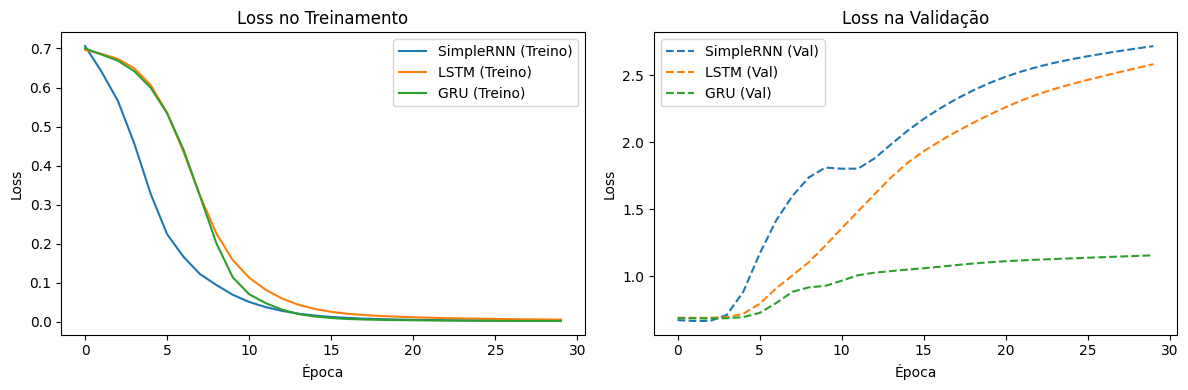

In [7]:
# Visualização das curvas de perda (Loss)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
for nome in modelos:
    plt.plot(historicos[nome]["loss"], label=f"{nome} (Treino)")
plt.title("Loss no Treinamento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
for nome in modelos:
    plt.plot(historicos[nome]["val_loss"], linestyle="--", label=f"{nome} (Val)")
plt.title("Loss na Validação")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


## Perguntas

**9.** Observe as curvas de perda (loss) de treinamento e validação. Como a GRU se comportou em termos de velocidade de convergência em comparação à SimpleRNN e à LSTM?  
**10.** Em termos de tempo de execução por época, qual modelo tende a ser mais rápido entre a GRU e a LSTM? Por que essa diferença ocorre?


# 6. Avaliação no Teste e Inferência de Novas Frases

Testaremos os modelos treinados em frases inéditas, incluindo exemplos com negação para observar a capacidade de capturar contexto.


In [8]:
print(f"{'Modelo':<10} | {'Parâmetros Totais':<18} | {'Loss Teste':<12} | {'Acurácia Teste':<14}")
print("-" * 60)
for nome, modelo in modelos.items():
    loss_t, acc_t = modelo.evaluate(X_test, y_test, verbose=0)
    print(f"{nome:<10} | {modelo.count_params():<18} | {loss_t:<12.4f} | {acc_t:<14.4f}")

# Avaliação qualitativa com frases contendo negação
novas_frases = np.array([
    "produto muito bom",
    "produto não é bom",
    "gostei da compra",
    "não gostei da compra"
])

novos_ids = vectorizador(novas_frases).numpy()

print("\n--- Predições (Probabilidade de ser Positiva) ---")
for i, frase in enumerate(novas_frases):
    print(f"\nFrase: '{frase}'")
    for nome, modelo in modelos.items():
        prob = modelo.predict(novos_ids[i:i+1], verbose=0)[0][0]
        print(f"  -> {nome:<10}: {prob:.4f}")


Modelo     | Parâmetros Totais  | Loss Teste   | Acurácia Teste
------------------------------------------------------------
SimpleRNN  | 333                | 2.9070       | 0.3750        
LSTM       | 645                | 3.1014       | 0.3750        
GRU        | 565                | 1.4402       | 0.6250        

--- Predições (Probabilidade de ser Positiva) ---

Frase: 'produto muito bom'
  -> SimpleRNN : 0.9924
  -> LSTM      : 0.9822
  -> GRU       : 0.9966

Frase: 'produto não é bom'
  -> SimpleRNN : 0.0014
  -> LSTM      : 0.0007
  -> GRU       : 0.0007

Frase: 'gostei da compra'
  -> SimpleRNN : 0.9975
  -> LSTM      : 0.9970
  -> GRU       : 0.9987

Frase: 'não gostei da compra'
  -> SimpleRNN : 0.0005
  -> LSTM      : 0.0004
  -> GRU       : 0.0005


## Perguntas

**11.** Compare as predições dos modelos para as frases "produto muito bom" e "produto não é bom". Os modelos conseguiram inverter a classificação ao identificar a negação "não"?    
**12.** Tendo em vista o trade-off entre **complexidade computacional (número de parâmetros)** e **capacidade de retenção de memória de longo prazo**, em quais cenários práticos de engenharia/PLN você escolheria usar uma **GRU** em vez de uma **LSTM**?
